# Predicting 30-Day Hospital Readmission in Patients with Diabetes

## 1. Problem Definition

### Objective
Predict whether a hospital encounter involving a patient with diabetes
will be followed by a recorded readmission within 30 days, using
information available at discharge.

### Intended Use
Explore whether a prediction model could help care teams prioritize
patients for post-discharge follow-up.

### Prediction Target
- Positive class (1): `readmitted` is `<30`.
- Negative class (0): `readmitted` is `>30` or `NO`.

### Unit of Observation
Each row represents a hospital encounter. A patient can appear in
multiple encounters, so patients must be kept separate across
training, validation, and test sets.

### Scope
This is an educational prototype using historical data.
Its performance does not establish suitability for clinical use.

## 2. Data Loading and Initial Inspection

The dataset contains hospital encounters involving patients with diabetes
from 130 US hospitals and integrated delivery networks between 1999 and 2008.

Source: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

Before cleaning, we inspect the dataset's dimensions, column types,
missing-value markers, patient identifiers, and target distribution.

In [189]:
import pandas as pd

In [190]:
df_raw = pd.read_csv(
    "data/raw/diabetic_data.csv",
    keep_default_na=False,
    na_values=["?", ""],
    dtype={"payer_code": "string"}
)


In [191]:
df_raw.shape

(101766, 50)

In [192]:
df_raw.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')

In [193]:
df_raw.nunique()

encounter_id                101766
patient_nbr                  71518
race                             5
gender                           3
age                             10
weight                           9
admission_type_id                8
discharge_disposition_id        26
admission_source_id             17
time_in_hospital                14
payer_code                      17
medical_specialty               72
num_lab_procedures             118
num_procedures                   7
num_medications                 75
number_outpatient               39
number_emergency                33
number_inpatient                21
diag_1                         716
diag_2                         748
diag_3                         789
number_diagnoses                16
max_glu_serum                    4
A1Cresult                        4
metformin                        4
repaglinide                      4
nateglinide                      4
chlorpropamide                   4
glimepiride         

In [194]:
df_raw.isnull().sum()

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum                   0
A1Cresult                       0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [195]:
missing_summary = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": df_raw.isna().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

missing_summary.round(2)

,missing_count,missing_pct
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [196]:
df = df_raw.copy()
columns_to_fill = ["medical_specialty",
    "payer_code",
    "race",
    "diag_1",
    "diag_2",
    "diag_3"]

df[columns_to_fill] = df[columns_to_fill].fillna("unknown")
df = df.drop(columns=["weight"]) #removing weight as we are missing 96.86% of the val

df[columns_to_fill].isnull().sum()

medical_specialty    0
payer_code           0
race                 0
diag_1               0
diag_2               0
diag_3               0
dtype: int64

In [197]:
test_columns = ["max_glu_serum", "A1Cresult"]
df[test_columns] = df[test_columns].replace("None", "not_measured")

### Missing-value handling

Categorical missing values were replaced with an explicit "unknown"
category to retain encounters without inventing information.

Weight was excluded from the initial model inputs because 96.86% of
values were missing.

For glucose and HbA1c test results, "None" was renamed "not_measured"
to preserve its documented meaning.

### Patient and Encounter Identifiers

Each row represents a hospital encounter, while a patient may have
multiple encounters.

We inspect encounter uniqueness and repeated patient identifiers.
All encounters belonging to the same patient will be assigned to
the same data split to evaluate generalization to unseen patients.

Identifiers will not be used as predictive features.

In [198]:
print(f"Total encounter: {len(df)}")
print(f"# unique encounterid:{df["encounter_id"].nunique()}")
print(f"# unique patient: {df["patient_nbr"].nunique()}")

Total encounter: 101766
# unique encounterid:101766
# unique patient: 71518


In [199]:
len(df["encounter_id"])

101766

In [200]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [201]:
readmitted_summary = pd.DataFrame({
    'count': round(df["readmitted"].value_counts(), 2),
    'pct': round(df["readmitted"].value_counts(normalize=True)*100, 2)
})

In [202]:
readmitted_summary

,count,pct
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


Readmissions within 30 days account for 11.16% of hospital encounters, making the positive class a minority. A model that always predicts no readmission within 30 days would achieve 88.84% accuracy, while failing to identify any early readmissions. Accuracy alone is therefore insufficient, therefore precision and recall will also be used to assess model performance.

### Excluding Encounters with a Recorded Death

This project predicts 30-day readmission for patients discharged alive,
with the intended use of supporting post-discharge follow-up.

Encounters with discharge disposition codes 11, 19, 20, or 21 indicate
a recorded death and are excluded from the study population.

The exclusion applies to individual encounters, not entire patient
histories. Earlier eligible encounters for the same patient are retained.

This rule is applied before patient-level splitting. The raw dataset
remains unchanged, and the number of excluded encounters is reported.

In [203]:
death_codes = [11, 19, 20, 21]
death_mask = df['discharge_disposition_id'].isin(death_codes)
print("Excluded encounters:", death_mask.sum())
df = df.loc[~death_mask].copy()


Excluded encounters: 1652


In [204]:
#checking if they were correctly deleted
df['discharge_disposition_id'].isin(death_codes).sum()

np.int64(0)

### Check for feature with unique value. They would not help.

In [205]:
df.nunique().sort_values()

examide                          1
citoglipton                      1
troglitazone                     2
acetohexamide                    2
tolbutamide                      2
glipizide-metformin              2
diabetesMed                      2
metformin-rosiglitazone          2
change                           2
glimepiride-pioglitazone         2
metformin-pioglitazone           2
readmitted                       3
gender                           3
tolazamide                       3
chlorpropamide                   4
glimepiride                      4
glipizide                        4
glyburide                        4
glyburide-metformin              4
acarbose                         4
miglitol                         4
nateglinide                      4
insulin                          4
pioglitazone                     4
rosiglitazone                    4
repaglinide                      4
A1Cresult                        4
max_glu_serum                    4
metformin           

The following columns contain only one unique value: citoglipton and examide.

These features are removed because they do not vary across encounters
and therefore cannot help distinguish readmitted from non-readmitted cases

In [206]:
df = df.drop(columns=['citoglipton', 'examide'])

## 3. Target Definition and Data Splitting

### 3.1 Binary Target Definition

The target `readmitted_30d` is set to 1 for readmissions within
30 days (`<30`) and 0 otherwise (`>30` or `NO`).
The original `readmitted` column is preserved for reference.

In [207]:
# Unexpected or missing labels must not silently become negative examples.
assert df["readmitted"].isin(["<30", ">30", "NO"]).all(), "Unexpected or missing readmission label"
df["readmitted_30d"] = (df["readmitted"] == "<30").astype(int)


In [208]:
# Verify the binary target against the original labels.
positive_count = (df["readmitted_30d"] == 1).sum()
original_positive_count = (df["readmitted"] == "<30").sum()
assert positive_count == original_positive_count, "Positive target count does not match"
assert df["readmitted_30d"].isin([0, 1]).all(), "Target must be binary"
print(f"Target checks passed: {positive_count:,} positive encounters.")


Target checks passed: 11,357 positive encounters.


### 3.2 Patient-Level Data Splitting

Patients are split into training, validation, and test sets.
All encounters belonging to the same patient remain in the same set.

Approximately 60% of patients are assigned to training, 20% to validation, and 20% to testing. Encounter proportions may differ because patients can have multiple encounters. The summary below is a split sanity check; the test set remains reserved for final evaluation.


In [209]:
from sklearn.model_selection import GroupShuffleSplit

In [210]:
#we split by numerical or catgegorical variable
numerical_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

categorical_features = [
    "race",
    "gender",
    "age",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "payer_code",
    "medical_specialty",
    "diag_1",
    "diag_2",
    "diag_3",
    "max_glu_serum",
    "A1Cresult",
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone",
    "change",
    "diabetesMed"
]

In [211]:
df[categorical_features] = df[categorical_features].astype(str)

In [212]:
splitter = GroupShuffleSplit(n_splits=1, 
                             test_size=0.20,
                             random_state=2)
full_train_pos, test_pos = next(splitter.split(df, groups=df["patient_nbr"]))

df_full_train = df.iloc[full_train_pos].copy()
df_test = df.iloc[test_pos].copy()

In [213]:
val_splitter = GroupShuffleSplit(n_splits=1,
                                 test_size=0.25,
                                 random_state=2)
train_pos, val_pos = next(val_splitter.split(df_full_train, groups=df_full_train["patient_nbr"]))
df_train = df_full_train.iloc[train_pos].copy()
df_val = df_full_train.iloc[val_pos].copy()

In [214]:
target = "readmitted_30d"
y_full_train = df_full_train[target]
y_test = df_test[target]
y_train = df_train[target]
y_val = df_val[target]


In [215]:
excluded = ["readmitted_30d", "readmitted", "patient_nbr", "encounter_id"]
x_full_train = df_full_train.drop(columns=excluded)
x_test = df_test.drop(columns=excluded)
x_train = df_train.drop(columns=excluded)
x_val = df_val.drop(columns=excluded)

In [216]:
print(len(x_full_train) == len(y_full_train))
print(len(x_train) == len(y_train))
print(len(x_test) == len(y_test))
print(len(x_val) == len(y_val))
print(x_train.index.equals(y_train.index))
print(x_test.index.equals(y_test.index))
print(x_full_train.index.equals(y_full_train.index))
print(x_val.index.equals(y_val.index))

True
True
True
True
True
True
True
True


In [217]:
train_patients = set(df_train["patient_nbr"])
val_patients = set(df_val["patient_nbr"])
test_patients = set(df_test["patient_nbr"])

print("Train / validation :", len(train_patients & val_patients))
print("Train / test :", len(train_patients & test_patients))
print("Validation / test :", len(val_patients & test_patients))

Train / validation : 0
Train / test : 0
Validation / test : 0


In [218]:
# Confirm that the split preserves all eligible encounters.
assert len(df_train) + len(df_val) + len(df_test) == len(df), "Split row count mismatch"
assert df["encounter_id"].is_unique, "Encounter IDs must be unique"
assert train_patients.isdisjoint(val_patients), "Patient overlap: train / validation"
assert train_patients.isdisjoint(test_patients), "Patient overlap: train / test"
assert val_patients.isdisjoint(test_patients), "Patient overlap: validation / test"

split_summary = pd.DataFrame({
    "encounter_count": [len(df_train), len(df_val), len(df_test)],
    "patient_count": [
        df_train["patient_nbr"].nunique(),
        df_val["patient_nbr"].nunique(),
        df_test["patient_nbr"].nunique()
    ],
    "readmission_rate_pct": [
        df_train[target].mean() * 100,
        df_val[target].mean() * 100,
        df_test[target].mean() * 100
    ]
}, index=pd.Index(["Train", "Validation", "Test"], name="split"))

print("Split checks passed: all encounters retained and no patient overlap.")
display(split_summary.round(2))


Split checks passed: all encounters retained and no patient overlap.


,encounter_count,patient_count,readmission_rate_pct
split,,,
Train,60063,42263,11.42
Validation,20048,14088,11.21
Test,20003,14088,11.25


## 4. Exploratory Data Analysis

In [219]:
import matplotlib.pyplot as plt

In [220]:
feature_summary = pd.DataFrame({
    "dtype": x_train.dtypes,
    "missing_pct": x_train.isna().mean() * 100,
    "unique_values": x_train.nunique(),
    "most_common_value": x_train.apply(
        lambda col: col.mode().iloc[0] if not col.mode().empty else None
    ),
    "most_common_pct": x_train.apply(
        lambda col: col.value_counts(normalize=True, dropna=False).max() * 100
    )
})

display(feature_summary.round(2))
display(x_train[numerical_features].describe().T)


,dtype,missing_pct,unique_values,most_common_value,most_common_pct
race,str,0.0,6,Caucasian,74.97
gender,str,0.0,3,Female,53.99
age,str,0.0,10,[70-80),25.35
admission_type_id,str,0.0,8,1,52.46
discharge_disposition_id,str,0.0,23,1,60.20
admission_source_id,str,0.0,16,7,56.09
time_in_hospital,int64,0.0,14,3,17.58
payer_code,str,0.0,17,unknown,39.55
medical_specialty,str,0.0,69,unknown,48.65
num_lab_procedures,int64,0.0,114,1,3.23


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,60063.0,4.390640,2.977370,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,60063.0,42.932005,19.644361,1.0,31.0,44.0,57.0,132.0
num_procedures,60063.0,1.338661,1.700720,0.0,0.0,1.0,2.0,6.0
num_medications,60063.0,15.986048,8.091546,1.0,10.0,15.0,20.0,81.0
number_outpatient,60063.0,0.373425,1.289318,0.0,0.0,0.0,0.0,42.0
number_emergency,60063.0,0.198791,0.970893,0.0,0.0,0.0,0.0,76.0
number_inpatient,60063.0,0.638180,1.288319,0.0,0.0,0.0,1.0,21.0
number_diagnoses,60063.0,7.414115,1.936458,1.0,6.0,8.0,9.0,16.0


In [221]:
print((df_train["number_outpatient"] == 0).mean() * 100)
print((df_train["number_inpatient"] == 0).mean() * 100)
print((df_train["number_emergency"] == 0).mean() * 100)

83.2808884005128
66.55511712701663
88.88333916054809


In [222]:
df_train["number_emergency"].value_counts().sort_index()

number_emergency
0     53386
1      4429
2      1245
3       445
4       228
5       103
6        50
7        48
8        36
9        22
10       25
11       17
12        6
13        7
14        1
15        2
16        1
19        2
20        1
21        1
25        1
28        1
42        1
46        1
54        1
63        1
64        1
76        1
Name: count, dtype: int64

High counts of previous emergency visits are rare. The maximum of 76 occurs in only one training encounter. These observations are retained because the available evidence does not establish that they are errors.

In [223]:
df_train["number_outpatient"].value_counts().sort_index()

number_outpatient
0     50021
1      5184
2      2153
3      1199
4       656
5       314
6       160
7        93
8        68
9        46
10       34
11       21
12       19
13       15
14       21
15       10
16       10
17        4
18        3
19        3
20        3
21        4
22        3
23        1
24        3
25        1
27        2
28        1
29        2
33        1
34        1
35        2
36        1
38        1
39        1
40        1
42        1
Name: count, dtype: int64

In [224]:
df_train["number_inpatient"].value_counts().sort_index()

number_inpatient
0     39975
1     11473
2      4471
3      1993
4       938
5       477
6       291
7       144
8        88
9        69
10       39
11       36
12       28
13       15
14        7
15        9
16        6
17        1
18        1
19        1
21        1
Name: count, dtype: int64

In [225]:
df_train[numerical_features].corrwith(df_train[target])

time_in_hospital      0.045329
num_lab_procedures    0.020934
num_procedures       -0.008913
num_medications       0.040098
number_outpatient     0.018964
number_emergency      0.062909
number_inpatient      0.174178
number_diagnoses      0.052555
dtype: float64

In [226]:
correlation = df_train[numerical_features].corr()

In [227]:
import seaborn as sns

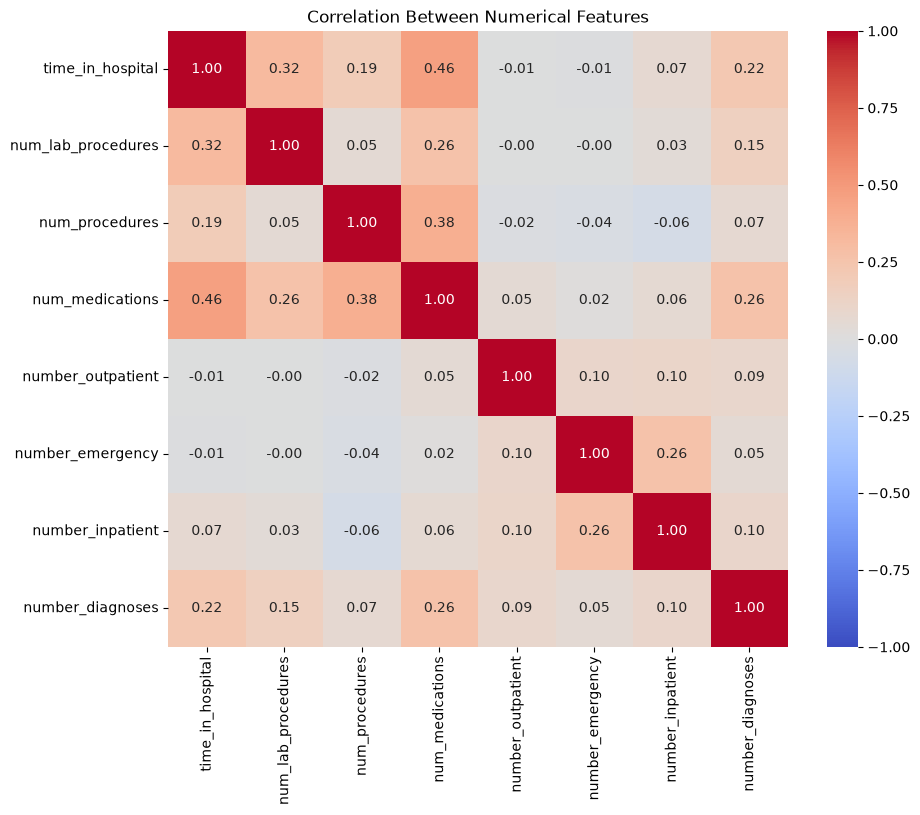

In [228]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Between Numerical Features")
plt.show()

In [229]:
from sklearn.metrics import mutual_info_score

In [230]:
def mutual_info_diabetes_score(series):
    return mutual_info_score(series, df_train[target])
mi = df_train[categorical_features].apply(mutual_info_diabetes_score)
mi.sort_values(ascending=False)

diag_1                      0.010489
diag_3                      0.009882
diag_2                      0.008953
discharge_disposition_id    0.006139
medical_specialty           0.002089
insulin                     0.001086
age                         0.000726
diabetesMed                 0.000525
payer_code                  0.000510
metformin                   0.000482
admission_source_id         0.000321
A1Cresult                   0.000283
change                      0.000212
max_glu_serum               0.000104
admission_type_id           0.000101
glipizide                   0.000088
race                        0.000080
pioglitazone                0.000079
rosiglitazone               0.000066
chlorpropamide              0.000041
glyburide                   0.000040
repaglinide                 0.000036
acarbose                    0.000029
glimepiride                 0.000027
tolbutamide                 0.000022
glyburide-metformin         0.000018
glipizide-metformin         0.000016
n

In [231]:
insulin_summary = df_train.groupby('insulin')[target].agg(["size", "mean"])
insulin_summary['mean']*=100
insulin_summary

,size,mean
insulin,,
Down,7234,14.597733
No,27884,10.195811
Steady,18195,11.360264
Up,6750,13.214815


In the training data, encounters involving an insulin dose decrease or increase have higher observed 30-day readmission rates than encounters with an unchanged dose or no insulin prescription. This association does not establish causality and may reflect differences in patient characteristics.

### EDA Conclusions

Readmission within 30 days is a minority outcome, so accuracy alone will not be sufficient for evaluation; precision and recall will also be examined.

Previous healthcare utilization is strongly right-skewed, with many zero counts and a small number of high values. These observations are retained because rarity alone does not establish a data error. Previous inpatient admissions show the strongest numerical correlation with the target, although the linear association remains modest (Pearson r approximately 0.17).

Diagnosis codes have the highest estimated mutual information among categorical features, but their many categories require cautious interpretation. Insulin dose changes are associated with higher observed readmission rates than an unchanged dose or no prescription. These findings describe associations, not causal effects.

The next step is to fit a logistic regression baseline with categorical encoding and numerical scaling learned on the training set. Model choices will be assessed on validation data, with the test set reserved for final evaluation.


In [232]:
#scaling the numerical features
x_train_scaled = x_train.copy()
x_val_scaled = x_val.copy()
x_test_scaled = x_test.copy()
x_full_train_scaled = x_full_train.copy()

In [233]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled[numerical_features] = scaler.fit_transform(
    x_train[numerical_features]
)

x_val_scaled[numerical_features] = scaler.transform(
    x_val[numerical_features]
)

x_test_scaled[numerical_features] = scaler.transform(
    x_test[numerical_features]
)
x_full_train_scaled[numerical_features] = scaler.transform(
    x_full_train[numerical_features]
)

### One-Hot Encoding
Categorical features are converted into binary indicator columns using
one-hot encoding. This includes categorical identifiers stored as integers,
such as admission type, discharge disposition, and admission source.

The encoder is fitted only on the training data and reused to transform
validation and test data, ensuring consistent feature columns. Categories
not observed during training will be handled without raising an error.

In [234]:
from sklearn.feature_extraction import DictVectorizer

train_dict = x_train_scaled.to_dict(orient='records')
val_dicts = x_val_scaled.to_dict(orient="records")

dv = DictVectorizer(sparse=False)

x_train = dv.fit_transform(train_dict)
x_val = dv.transform(val_dicts)

## Baseline Logistic Regression

In [237]:
from sklearn.linear_model import LogisticRegression
b_lr = LogisticRegression(max_iter=1000)
b_lr.fit(x_train, y_train)

y_val_proba = b_lr.predict_proba(x_val)[:, 1]
print(y_val_proba)

[0.15075705 0.08039026 0.13679875 ... 0.02828388 0.08721554 0.19599564]


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay
)

def evaluate_model(y_true, y_proba, model_name, threshold , plot=True):
    y_pred = (y_proba >= threshold)

    results = {
        "model": model_name,
        "threshold": threshold,
        "roc_auc": roc_auc_score(y_true, y_proba),
        "average_precision": average_precision_score(y_true, y_proba),
        "ap_baseline": y_true.mean(),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "alerts": int(y_pred.sum()),
        "alert_rate": y_pred.mean()
    }

    if plot:
        ConfusionMatrixDisplay.from_predictions(
            y_true,
            y_pred,
            labels=[0, 1],
            display_labels=["No early readmission", "Readmission <30 days"],
            cmap="Blues",
            values_format="d",
            colorbar=False
        )

        plt.title(f"{model_name} — Threshold {threshold}")
        plt.tight_layout()
        plt.show()

    return results

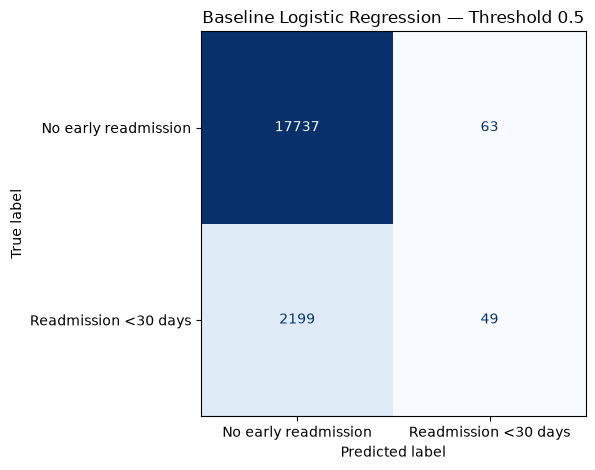

,model,threshold,roc_auc,average_precision,ap_baseline,precision,recall,alerts,alert_rate
0,Baseline Logistic Regression,0.5,0.658,0.207,0.112,0.438,0.022,112,0.006


In [262]:
b_lr_results = evaluate_model(
    y_val,
    y_val_proba,
    threshold=0.5,
    model_name="Baseline Logistic Regression"
)

display(pd.DataFrame([b_lr_results]).round(3))

### Baseline Logistic Regression — Validation Results

The model achieves a ROC-AUC of **0.658** and an average precision of
**0.207**, compared with a constant-score baseline of **0.112**. These
results indicate useful but modest ranking performance.

At a decision threshold of **0.5**, the model flags **112 of 20,048
encounters** (approximately **0.56%**). Of these alerts, **49 are correct**
and **63 are false positives**, giving a precision of **43.75%**.

However, the model misses **2,199 of the 2,248 actual readmissions**.
Recall is therefore only **2.18%**, which is insufficient for the
project's objective of identifying encounters at risk of early readmission.

The threshold of 0.5 produces too few alerts to achieve high recall.
Lower thresholds will be explored on the validation set, assessing the
trade-off between recall, precision, and follow-up workload. Changing
the threshold will not improve the model's underlying ranking performance.

These results provide a reference for regularization tuning and comparison
with tree-based models. The test set remains reserved for final evaluation.

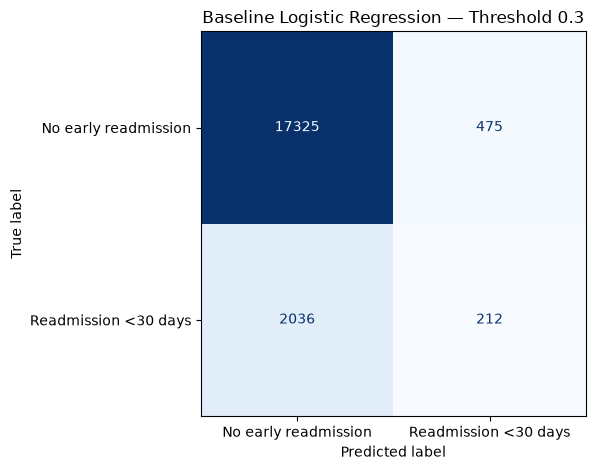

,model,threshold,roc_auc,average_precision,ap_baseline,precision,recall,alerts,alert_rate
0,Baseline Logistic Regression,0.3,0.658,0.207,0.112,0.309,0.094,687,0.034


In [263]:
b_lr_results = evaluate_model(
    y_val,
    y_val_proba,
    threshold=0.3,
    model_name="Baseline Logistic Regression"
)

display(pd.DataFrame([b_lr_results]).round(3))

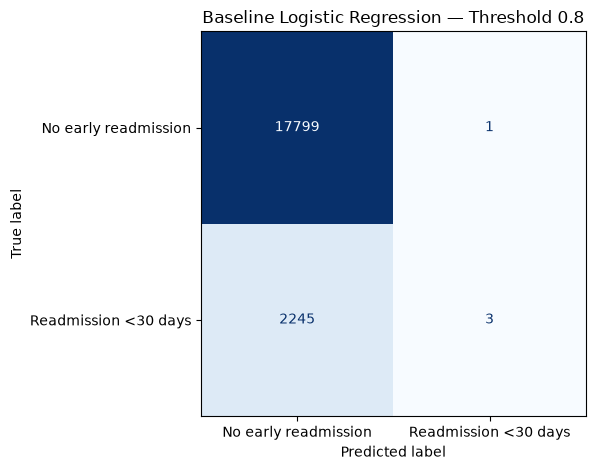

,model,threshold,roc_auc,average_precision,ap_baseline,precision,recall,alerts,alert_rate
0,Baseline Logistic Regression,0.8,0.658,0.207,0.112,0.75,0.001,4,0.0


In [264]:
b_lr_results = evaluate_model(
    y_val,
    y_val_proba,
    threshold=0.8,
    model_name="Baseline Logistic Regression"
)

display(pd.DataFrame([b_lr_results]).round(3))

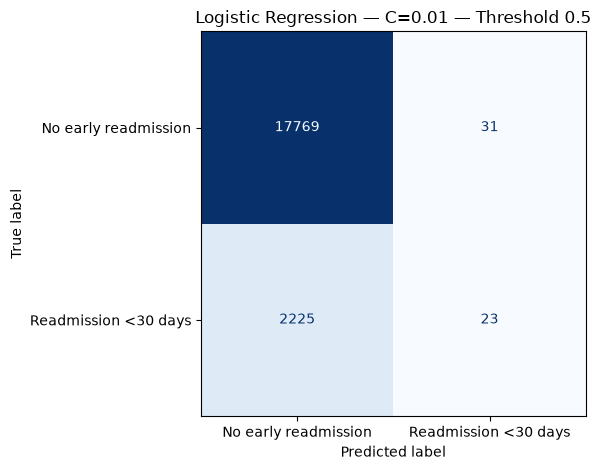

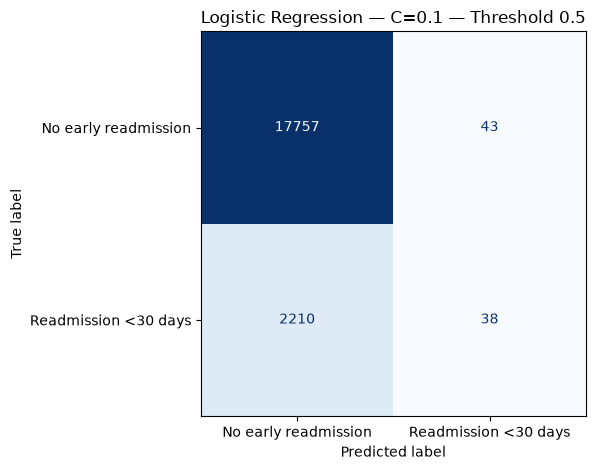

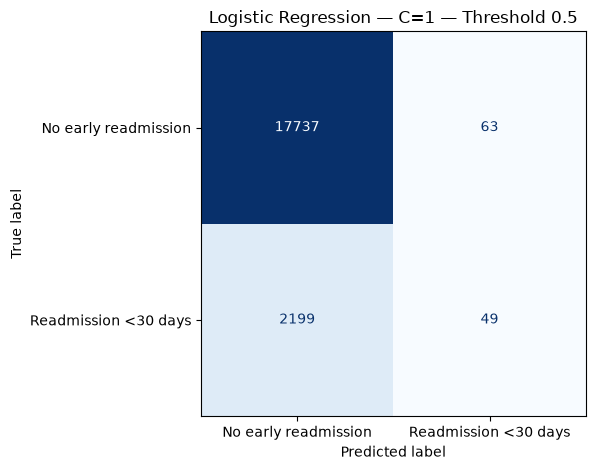

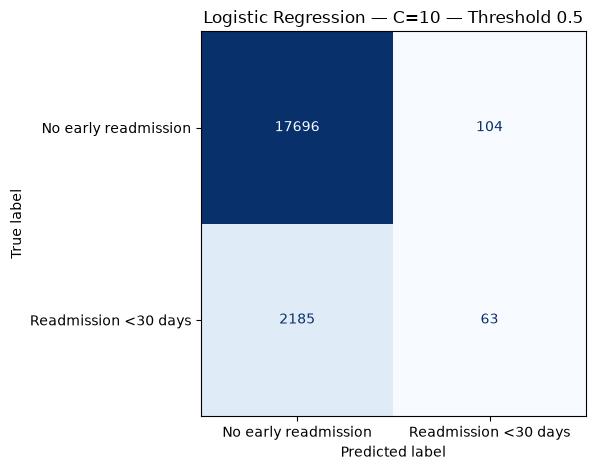

,model,threshold,roc_auc,average_precision,ap_baseline,precision,recall,alerts,alert_rate,C
1,Logistic Regression — C=0.1,0.5,0.668,0.215,0.112,0.469,0.017,81,0.004,0.10
0,Logistic Regression — C=0.01,0.5,0.667,0.211,0.112,0.426,0.010,54,0.003,0.01
2,Logistic Regression — C=1,0.5,0.658,0.207,0.112,0.438,0.022,112,0.006,1.00
3,Logistic Regression — C=10,0.5,0.646,0.197,0.112,0.377,0.028,167,0.008,10.00


In [266]:
C_values = [0.01, 0.1, 1, 10]
results = []
for c in C_values:
    lr = LogisticRegression(max_iter=1000, C=c)
    lr.fit(x_train, y_train)

    y_val_proba = lr.predict_proba(x_val)[:, 1]
    result = evaluate_model(
        y_val,
        y_val_proba,
        model_name=f"Logistic Regression — C={c}",
        threshold=0.5,
        plot=True
    )

    result["C"] = c
    results.append(result)

    #display(pd.DataFrame([result]).round(3))

# Compare all four models.
comparison = pd.DataFrame(results)
display(comparison.sort_values("average_precision", ascending=False).round(3))

### Random forest

In [267]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1)
rf.fit(x_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

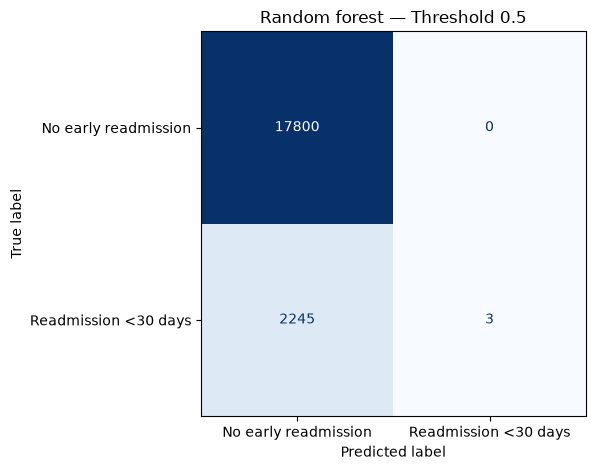

,model,threshold,roc_auc,average_precision,ap_baseline,precision,recall,alerts,alert_rate
0,Random forest,0.5,0.65,0.197,0.112,1.0,0.001,3,0.0


In [271]:
y_val_proba = rf.predict_proba(x_val)[:, 1]
rf_result = evaluate_model(
    y_val,
    y_val_proba,
    threshold=0.5,
    model_name="Random forest"
)

display(pd.DataFrame([rf_result]).round(3))

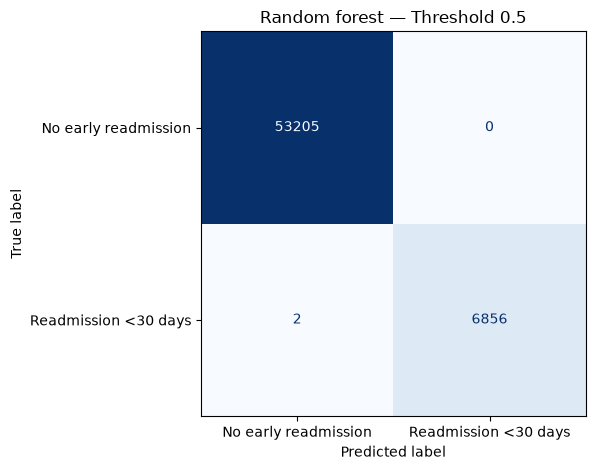

,model,threshold,roc_auc,average_precision,ap_baseline,precision,recall,alerts,alert_rate
0,Random forest,0.5,1.0,1.0,0.114,1.0,1.0,6856,0.114


In [272]:
y_train_proba = rf.predict_proba(x_train)[:, 1]
rf_result = evaluate_model(
    y_train,
    y_train_proba,
    threshold=0.5,
    model_name="Random forest"
)

display(pd.DataFrame([rf_result]).round(3))

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1)
rf.fit(x_train, y_train)

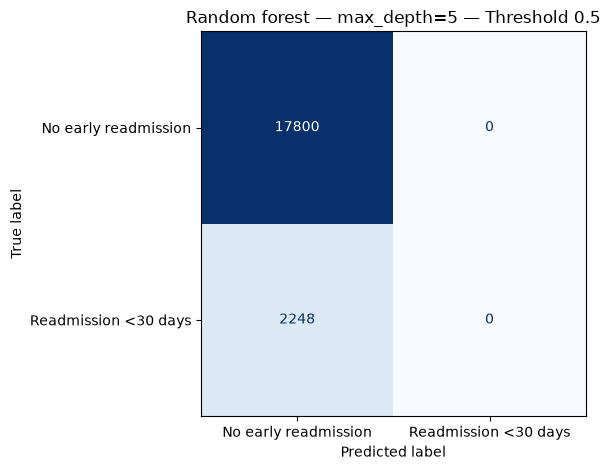

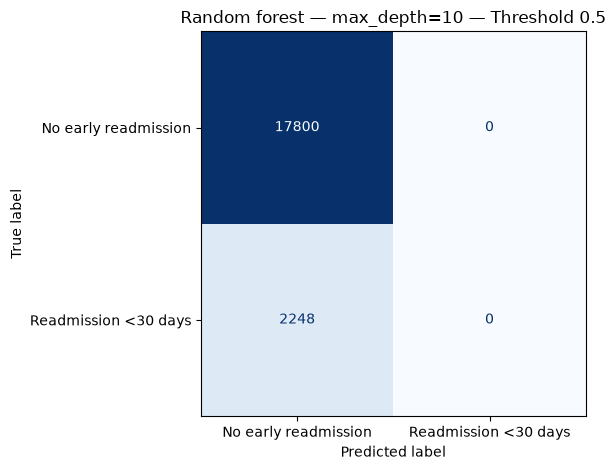

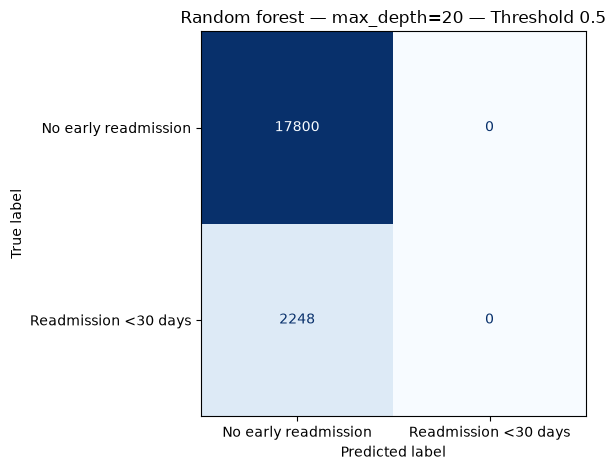

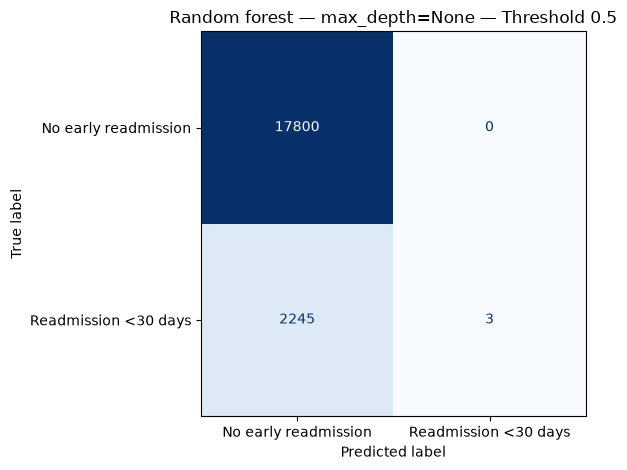

,model,threshold,roc_auc,average_precision,ap_baseline,precision,recall,alerts,alert_rate,max_depth
2,Random forest — max_depth=20,0.5,0.660,0.210,0.112,0.0,0.000,0,0.0,20.0
1,Random forest — max_depth=10,0.5,0.657,0.205,0.112,0.0,0.000,0,0.0,10.0
0,Random forest — max_depth=5,0.5,0.650,0.197,0.112,0.0,0.000,0,0.0,5.0
3,Random forest — max_depth=None,0.5,0.650,0.197,0.112,1.0,0.001,3,0.0,NaN


In [273]:
max_depth = [5, 10, 20, None]
results = []
for d in max_depth:
    rf = RandomForestClassifier(n_estimators=100,max_depth=d, random_state=1, n_jobs=-1)
    rf.fit(x_train, y_train)

    y_val_proba = rf.predict_proba(x_val)[:, 1]
    result = evaluate_model(
        y_val,
        y_val_proba,
        model_name=f"Random forest — max_depth={d}",
        threshold=0.5,
        plot=True
    )

    result["max_depth"] = d
    results.append(result)

    #display(pd.DataFrame([result]).round(3))

# Compare all four models.
comparison = pd.DataFrame(results)
display(comparison.sort_values("average_precision", ascending=False).round(3))
